![Banner](../../../../Images/Banner/07_remote_sensing/09_02_banner_rs_optical.png)


# MODIS: Global Monitoring Every Day

MODIS (Moderate Resolution Imaging Spectroradiometer) is a NASA instrument on Terra (morning orbit, launched December 1999) and Aqua (afternoon orbit, launched May 2002).


## Overview

Together they image most of the Earth every one to two days in 36 bands. A MODIS product may be a spectral image or a processed measurement such as a vegetation index, land surface temperature, snow cover or fire. This notebook shows how those products are organised and how to turn them into analysis-ready time series with `geolattice.rsense`.


## Core concepts

### Learning objectives

1. Know the main MODIS products and their spatial/temporal resolutions.
2. Understand the sinusoidal grid and tile system, and reproject MODIS data correctly.
3. Apply product scale factors and fill values.
4. Decode QA bit fields and mask clouds and shadows.
5. Build vegetation-index time series, maximum-value composites and phenology maps.
6. Recognise the mixed-pixel problem when comparing MODIS with Landsat.
7. Mosaic adjacent MODIS tiles, reproject them, clip to a national boundary and store the NDVI cube as Zarr.

### Contents

1. Key characteristics
2. Spatial resolution
3. Spectral bands
4. Products
5. Product names
6. Where to get MODIS data
7. A typical processing workflow
8. Preprocessing considerations
9. Applications
10. Limitations
11. Data
12. Setup
13. The MODIS product family and the sinusoidal grid
14. Loading real MODIS data
15. Downloading a year of MODIS data
16. Scale factors and fill values
17. Decoding QA bits and masking clouds
18. Vegetation index time series and maximum-value composites
19. Smoothing and land surface phenology
20. MODIS versus Landsat: resolution and mixed pixels
21. Bangladesh NDWI, 2020
22. Summary, exercises and references


## Key characteristics

| Characteristic      | Description                                                                                  |
| ------------------- | -------------------------------------------------------------------------------------------- |
| Sensor              | Moderate Resolution Imaging Spectroradiometer                                                |
| Satellite platforms | Terra and Aqua                                                                               |
| Spectral coverage   | 36 spectral bands                                                                            |
| Wavelength range    | Approximately 0.4–14.4 micrometers                                                           |
| Spatial resolution  | 250 m, 500 m, and 1,000 m, depending on band                                                 |
| Swath width         | Approximately 2,330 km                                                                       |
| Global coverage     | Approximately every 1–2 days, depending on location and product                              |
| Historical record   | Terra observations from 2000 and Aqua observations from 2002, with product-specific coverage |
| Main applications   | Agriculture, forestry, hydrology, climate, land cover, and disaster monitoring               |


## Spatial resolution

Spatial resolution describes the approximate ground area represented by each pixel.

1. **250 m resolution**: Each pixel represents approximately 250 m × 250 m, or 6.25 hectares. Used by selected red and near-infrared bands.

2. **500 m resolution**: Each pixel represents approximately 25 hectares. Common for vegetation indices, reflectance, and land-cover products.

3. **1 km resolution**: Each pixel represents approximately 100 hectares. Common for land surface temperature and various atmospheric or environmental products.

These are nominal resolutions at or near nadir (directly beneath the satellite). Actual pixel footprints can become larger and more distorted toward the edges of the satellite swath.

Important: A 250 m MODIS image cannot reliably identify individual small fields, wells, or narrow rivers. It is best suited to regional and landscape-scale analysis.


## Spectral bands

MODIS measures reflected sunlight and emitted thermal radiation at different wavelengths. These measurements help scientists distinguish vegetation, water, soil, clouds, and other surface or atmospheric features. 

The main spectral regions are:

**1. Visible light**:  Approximately 0.4–0.7 µm. Useful for natural-color images, clouds, water bodies, and land-cover patterns.

**2. Near-infrared (NIR)**: Strongly reflected by healthy vegetation. Useful for vegetation monitoring and NDVI calculation.

**3. Shortwave infrared (SWIR)**: Sensitive to vegetation water content, moisture conditions, soil properties, and burned areas.

**4. Thermal infrared**: Measures emitted radiation used to estimate land surface temperature and detect thermal anomalies.


### Bands used for vegetation

| MODIS band | Approximate wavelength | Main use                                           |
| ---------- | ---------------------- | -------------------------------------------------- |
| Band 1     | 0.65 µm                | Red reflectance; vegetation indices                |
| Band 2     | 0.86 µm                | Near-infrared; vegetation indices                  |
| Band 3     | 0.47 µm                | Blue reflectance; atmospheric correction           |
| Band 4     | 0.56 µm                | Green reflectance; vegetation and water studies    |
| Band 6     | 1.64 µm                | Moisture-sensitive vegetation and surface analysis |
| Band 7     | 2.13 µm                | Surface and vegetation characterization            |
| Band 31    | 11.0 µm                | Thermal measurements and surface temperature       |
| Band 32    | 12.0 µm                | Thermal measurements and surface temperature       |

Wavelengths are rounded, and exact band characteristics depend on the sensor specification. 


## Products

MODIS data are distributed in different scientific products. You should choose a product according to your research objective rather than treating all MODIS images as interchangeable.

**A. True-color and surface-reflectance images**

These resemble photographs of the Earth's surface. Surface-reflectance products correct for atmospheric effects and are useful for land-cover mapping, surface characterization, and change detection.

Examples: MOD09, MYD09; MOD02/MYD02 for calibrated radiances.

**B. Vegetation index images (NDVI and EVI)**

These indicate vegetation greenness and help monitor crop development, vegetation stress, seasonal growth, and ecosystem productivity.

Examples: MOD13Q1 and MYD13Q1 at 250 m, with 16-day composites.


**C. Land surface temperature (LST)**

Estimates the radiometric temperature of the land surface, which can differ substantially from air temperature. Useful for heat-stress studies, drought assessment, and evapotranspiration modeling.

Examples: MOD11A1 and MYD11A1, daily nominal 1 km products.


**D. Land-cover images**

Classify pixels into categories such as forest, cropland, grassland, urban areas, and water. Useful for mapping landscape change and studying relationships between land use and environmental conditions.

Example: MCD12Q1, an annual land-cover product at 500 m.

**E. Fire and burned-area products**

Detect active fire locations and map areas affected by fire. Useful for wildfire monitoring, smoke studies, and ecosystem disturbance assessment.

Examples: MOD14/MYD14 active-fire products and MCD64A1 burned-area product.


**F. Evapotranspiration (ET) products**

Estimate water transferred from land to the atmosphere through evaporation and plant transpiration. Useful for agricultural water-use assessment, drought analysis, and hydrological modeling.

Example: MOD16A2GF, an 8-day gap-filled ET product at 500 m.

NASA provides the official catalogue of MODIS land, vegetation, temperature, evapotranspiration, fire, and other products. 


## Product names

MODIS datasets commonly have identifiers such as `MOD13Q1`, `MYD13Q1`, and `MOD11A1`.

| Prefix or suffix | Meaning                                                                 |
| ---------------- | ----------------------------------------------------------------------- |
| `MOD`            | Terra MODIS                                                             |
| `MYD`            | Aqua MODIS                                                              |
| `MCD`            | Combined Terra and Aqua product                                         |
| `13`             | Vegetation-index product family                                         |
| `11`             | Land surface temperature product family                                 |
| `Q1`             | Commonly denotes a 250 m, 16-day vegetation-index product in `MOD13Q1`  |
| `A1`             | Commonly denotes a daily tiled product in identifiers such as `MOD11A1` |
| `A2`             | Commonly denotes an 8-day product in identifiers such as `MOD16A2`      |

The exact meaning depends on the complete product identifier. The product's collection version, processing level, and quality flags must also be checked before analysis.


## Where to get MODIS data

There are several reliable ways to access MODIS data, depending on whether you need a quick visualization, a research-ready raster, or a long time series.

1\. NASA Worldview

Best for viewing satellite imagery, exploring dates, comparing environmental events, and creating visualizations.

Website: [NASA Worldview](https://worldview.earthdata.nasa.gov/)

2\. NASA Earthdata Search

Best for finding, filtering, and downloading scientific MODIS datasets by location, date, and product.

Website: [NASA Earthdata Search](https://search.earthdata.nasa.gov/)


3\. Google Earth Engine (GEE)

Best for processing long MODIS time series, calculating vegetation indices, creating regional composites, and extracting raster values for thousands of locations.

Website: [Google Earth Engine](https://earthengine.google.com/)

4\. NASA LP DAAC

Best for downloading and processing MODIS land products, including surface reflectance, vegetation indices, land cover, temperature, and evapotranspiration.

Website: [NASA LP DAAC](https://lpdaac.usgs.gov/)

For large research projects, Google Earth Engine is often convenient because it allows you to process data without downloading every original satellite file. For reproducible local workflows, downloaded products can be processed using Python, R, GDAL, or QGIS.

Instrument specifications and product documentation: [NASA MODIS](https://modis.gsfc.nasa.gov/).


## A typical processing workflow

A typical workflow looks like this:

Step 1. Define the study area and dates

Country, watershed, agricultural region, or grid

Step 2. Select the MODIS product

NDVI, surface reflectance, LST, ET, or land cover

Step 3. Apply quality control

Screen clouds, invalid pixels, poor retrievals, and fill values

Step 4. Prepare spatial data

Clip, reproject if needed, resample carefully, and align grids

Step 5. Build temporal composites

Daily, 8-day, 16-day, monthly, or seasonal summaries

Step 6. Analyze and validate

Maps, trends, raster statistics, machine learning, or spatiotemporal modeling


## Preprocessing considerations

- Scale factors: Many MODIS scientific products store integer values that must be multiplied by documented scale factors and adjusted for any specified offsets.
- Quality assurance (QA): A pixel's value alone may not indicate whether the observation is reliable. Inspect the product-specific QA fields.
- Cloud contamination: Clouds and cloud shadows can make surface observations unusable.
- Temporal compositing: A 16-day product is not equivalent to a daily observation; it summarizes or selects observations over a time window.
- Spatial alignment: Use consistent projections, pixel grids, and resolutions when combining MODIS with other satellite products.
- Missing observations: Do not automatically replace missing pixels with zero. Use a documented masking, interpolation, or imputation procedure appropriate to the analysis.


## Applications

MODIS is particularly useful when environmental variables must be observed repeatedly over large areas. For groundwater research, however, MODIS generally provides indirect indicators of groundwater-related processes, not direct measurements of groundwater levels.

Agricultural monitoring: Use NDVI, EVI, land surface temperature, and evapotranspiration to study crop growth, seasonal patterns, vegetation stress, and irrigation demand.

Drought monitoring: Combine vegetation indices, land surface temperature, precipitation, and evapotranspiration to identify periods of agricultural and environmental water stress.

Hydrological analysis:Use water-related products, ET estimates, land cover, and vegetation observations to investigate water balance, seasonal surface-water dynamics, and land–atmosphere interactions.


## Limitations

| Limitation                     | Implication for research                                                         |
| ------------------------------ | -------------------------------------------------------------------------------- |
| Moderate spatial resolution    | Small fields, narrow waterways, and local features may not be resolved reliably. |
| Clouds and atmospheric effects | Surface observations may be missing or contaminated.                             |
| Composite products             | A composite may not represent the conditions at a specific day or hour.          |
| Mixed pixels                   | A single pixel may include several land-cover types.                             |
| Retrieval uncertainty          | ET and LST estimates have product-specific uncertainties.                        |
| Indirect hydrological signals  | Vegetation and temperature do not directly measure groundwater depth.            |

For finer agricultural mapping, Landsat and Sentinel-2 can complement MODIS. For regional groundwater storage changes, GRACE and GRACE-FO provide complementary information, but their spatial resolution is much coarser than a 1 km grid. Ground-based well measurements remain essential for validating groundwater-level forecasts.


## Data

| Dataset | Source | Role |
|---|---|---|
| Real MOD09Q1 surface reflectance, 8-day, 250 m, tile h08v05, 2024 | Microsoft Planetary Computer, downloaded live in *Downloading a year of MODIS data* with `geolattice.rsense.get_images` | Executed analysis, from the download through the mixed-pixel comparison |
| Landsat 9 C2 L2 surface reflectance, 8 July 2024, Las Vegas (90 m, 7 bands) | Real scene, used to locate example pixels and for the resolution comparison | Executed analysis |
| NLCD 2021 land cover (30 m, resampled to the MODIS grid) | USGS, via the cloud-optimised national mosaic | Groups MODIS pixels by land-cover type |
| Terra MOD09Q1, tiles h25v06 and h26v06, 2020–2024 | Microsoft Planetary Computer, downloaded in *Bangladesh NDWI, 2020* | Bangladesh NDVI cube |
| Bangladesh county boundaries and BUTM projection | `Data/00_shared/data_geostatistics/BD_Banladesh_BUTM.shp` and `.prj` | Clip and reprojection target |



> **This notebook downloads real data.** *Downloading a year of MODIS data* calls `geolattice.rsense.get_images` to pull every
> 2024 MOD09Q1 composite over Las Vegas straight from Microsoft Planetary Computer (no account
> needed) — about 44 real eight-day composites, roughly 130 small GeoTIFFs. Everything after
> that — scaling, QA masking, indices, smoothing, phenology, mixed pixels — runs on those real
> pixels, clouds and all. It needs internet; `ONLINE` (set in *Setup*) reports whether the
> catalogue is reachable.


## Setup

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

import json
import numpy as np
import pandas as pd
import xarray as xr
import rasterio
import matplotlib.pyplot as plt
from pyproj import Transformer

import geolattice.rsense as rs
from geolattice.rsense.optical.sensors import modis
from geolattice.rsense.get_images import get_images, search_images
from geolattice.network import is_online

rasterio.Env(CPL_LOG="/dev/null").__enter__()
plt.rcParams.update({"figure.dpi": 110})
ONLINE = is_online("https://planetarycomputer.microsoft.com/api/stac/v1")
# "cpu" keeps this notebook's land-cover/group arrays (plain numpy) and MODIS data on the
# same backend; "auto" would move MODIS data to the GPU on a CUDA machine and break code
# below that mixes it with plain numpy arrays.
print("geolattice.rsense", rs.__version__, "| backend:", rs.set_backend("cpu"),
      "| Planetary Computer reachable:", ONLINE)

geolattice.rsense 0.2.0.dev0 | backend: cpu | Planetary Computer reachable: True


In [2]:
# This section defines helper functions and data references for working with remote sensing tutorial data.
#
# 1. It creates a local "data" directory if it doesn't exist.
# 2. Sets up URL patterns for accessing remote files, including GitHub and SentinelHub repositories.
# 3. Builds a dictionary (URLS) mapping friendly filenames (e.g. "landsat_las_vegas.tif") to their remote download locations.
#    - The dictionary covers diverse datasets, including Landsat, ECOSTRESS, and Sentinel-2 example scenes.
# 4. Defines `fetch(name)`:
#    - Checks if a file exists locally; if not, downloads it from the relevant URL and stores it in "data/".
#    - Returns a Path object to the local file.
# 5. Sets up a download link and a color-class dictionary for the 2021 National Land Cover Dataset (NLCD).
# 6. Defines `nlcd_for(template, name="nlcd_window")`:
#    - Downloads and resamples only the window of NLCD data matching the spatial extent and CRS of a provided xarray DataArray/template.
#    - Uses cloud-optimized GeoTIFF and cloud-native rasterio/rioxarray access for efficiency.
#    - Caches the resampled tile locally, and forces output type/int16 and nodata convention.

# This section is about getting and managing example remote sensing data files, and making a utility for quick access/cropping with land cover maps (NLCD).
# It's designed to make it easy to download and use standard raster files for the tutorial, even if they're big, and to let you work with just the window you need.

from pathlib import Path   # Lets you handle files & folders nicely
import urllib.request      # Lets you download files from the internet

DATA = Path("../../../../Data/08_remote_sensing/08_02_optical")        # Define a folder called 'data' to keep everything organized
DATA.mkdir(exist_ok=True)  # Make the folder if it isn't already there

# These are base URLs to datasets used in this tutorial:
GH = "https://github.com/opengeos/datasets/releases/download"  # Used for hosting big downloadable data files (GeoTIFF, etc.)
RAW = "https://raw.githubusercontent.com"  # Used for direct file access from GitHub repositories
EOP = f"{RAW}/sentinel-hub/eo-learn/develop/example_data/TestEOPatch"  # A specific base for SentinelHub's eo-learn tutorial dataset

# This dictionary links short, friendly filenames (what you'll use locally) to their online location
# That way, you just refer to (for example) "landsat_las_vegas.tif", and the code knows where to find and download it.
URLS = {
    # Example: Las Vegas, from Landsat 9 (July 2024). 90m resolution, 7 bands.
    "landsat_las_vegas.tif": f"{GH}/raster/landsat_las_vegas.tif",
    # Example: Peru, every 5 years from 1985 to 2020. Landsat composites as small TIFFs.
    **{f"pucallpa_{y}.tif": f"{RAW}/opengeos/data/main/landsat/{y}.tif" for y in range(1985, 2021, 5)},
    # Example: ECOSTRESS land surface temperature, SoCal, April 2023.
    "ecostress_lst.tif": f"{GH}/raster/ECOv002_L2T_LSTE_26860_001_10SGD_20230401T203733_0710_01_LST.tif",
    # Example: Central Sierra Nevada Landsat 7 + a Digital Elevation Model (DEM)
    "landsat.tif": f"{GH}/raster/landsat.tif",
    "dem_90m.tif": f"{GH}/book/dem_90m.tif",
    # A sample COG (cloud-optimized GeoTIFF)
    "cog.tif": f"{GH}/raster/cog.tif",
    # Sentinel-2 southern Slovenia time series (eo-learn test eopatch)
    "s2_bands.npy": f"{EOP}/data/BANDS-S2-L1C.npy",
    "s2_clp.npy": f"{EOP}/data/CLP.npy",
    "s2_clm.npy": f"{EOP}/mask/CLM.npy",
    "s2_lulc.npy": f"{EOP}/mask_timeless/LULC.npy",
    "s2_dem.npy": f"{EOP}/data_timeless/DEM.npy",
    "s2_timestamps.json": f"{EOP}/timestamps.json",
    "s2_bbox.geojson": f"{EOP}/bbox.geojson",
}

def fetch(name):
    """
    Download a file by its nickname if it isn't already stored locally
    and return the local path.
    This makes sure you never download anything twice, and you just call
    fetch("landsat.tif") and get the data, guaranteed!
    """
    path = DATA / name
    if not path.exists():
        print(f"Downloading {name} ...")  # Let the user know what's happening
        urllib.request.urlretrieve(URLS[name], path)  # Fetch it!
    return path   # Return the ready-to-use file path

# -- NLCD (National Land Cover Database) info
# This is a U.S.-wide map where every pixel is a land cover class code:
NLCD_URL = f"{GH}/raster/nlcd_2021_land_cover_90m.tif"
# Each land cover code means a category, with a readable name and a color (for plots)
NLCD_CLASSES = {
    11: ("Open water", "#466b9f"), 21: ("Developed, open", "#dec5c5"),
    22: ("Developed, low", "#d99282"), 23: ("Developed, medium", "#eb0000"),
    24: ("Developed, high", "#ab0000"), 31: ("Barren", "#b3ac9f"),
    41: ("Deciduous forest", "#68ab5f"), 42: ("Evergreen forest", "#1c5f2c"),
    43: ("Mixed forest", "#b5c58f"), 52: ("Shrub/scrub", "#ccb879"),
    71: ("Grassland", "#dfdfc2"), 81: ("Pasture/hay", "#dcd939"),
    82: ("Cultivated crops", "#ab6c28"), 90: ("Woody wetlands", "#b8d9eb"),
    95: ("Herbaceous wetlands", "#6c9fb8")
}

def nlcd_for(template, name="nlcd_window"):
    """
    For dummies: Give me land cover data that matches my area of interest/grid!
    
    What this does:
      - Given ANY xarray/raster 'template' (with bounds, res, projection),
      - Clips just the part of the big NLCD raster covering that extent (using HTTP, so it's fast even for huge rasters),
      - Reprojects it (warps to template's pixel size & projection, using nearest neighbor so codes stay codes),
      - Saves a window of that data locally (so next time it's instant),
      - Returns an xarray DataArray matching your template, with INT16 type and zero for no data (background).
    
    This is very efficient, so you can overlay NLCD with any other product easily.
    """
    from rasterio.enums import Resampling
    cache = DATA / f"{name}.tif"
    if not cache.exists():
        # Only do the heavy lifting when the file isn't already ready
        import rasterio, rioxarray
        from rasterio.warp import transform_bounds
        # The VSICURL trick lets rasterio/rioxarray read just what we want from a giant cloud-hosted TIFF
        with rasterio.Env(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR"):
            # Open remote NLCD raster (no download)
            src = rioxarray.open_rasterio("/vsicurl/" + NLCD_URL)
            # Figure out what portion we need (matching the template's bbox, but transformed to the NLCD's CRS)
            b = transform_bounds(template.rio.crs, src.rio.crs, *template.rio.bounds())
            # Extract just that box, drop band dimension, load the data into memory
            win = src.rio.clip_box(*b).squeeze("band", drop=True).load()
        # Write the window to disk for future re-use (as a normal file)
        rs.write(win, cache, cog=False)
    # Now read that local tile (quick, masked=False disables masked arrays)
    win = rs.read(cache, masked=False).squeeze("band", drop=True).rio.write_nodata(0)
    # Warp (resample/reproject) to match the template's pixel arrangement (nearest neighbor preserves codes, no interpolation)
    out = win.rio.reproject_match(template, resampling=Resampling.nearest, nodata=0)
    # Make sure the result is a normal integer array (no floats!), all no-data is 0, and return
    return out.astype("int16").rio.write_nodata(0)

## The MODIS product family and the sinusoidal grid

MODIS data are distributed as *products*: geophysical variables at a fixed resolution and
compositing period. Product names encode the platform (**MOD** = Terra, **MYD** = Aqua,
**MCD** = combined), the product number, and the collection (currently 061).


In [3]:
# This code creates a DataFrame listing important MODIS remote sensing products, their main variables, spatial resolution, and temporal period.
# Each row in the DataFrame represents a MODIS product and includes:
# - The product short name (e.g., MOD09GA)
# - A description of the variable(s) in that product
# - The native spatial resolution (e.g., 500 m, 1 km)
# - The compositing period (e.g., daily, 16-day)
products = pd.DataFrame([
    ("MOD09GA", "Surface reflectance, bands 1-7", "500 m (b1-2 also 250 m)", "Daily"),
    ("MOD09A1", "Surface reflectance, best pixel", "500 m", "8-day"),
    ("MOD13Q1", "NDVI / EVI", "250 m", "16-day"),
    ("MOD11A1", "Land surface temperature & emissivity", "1 km", "Daily (day & night)"),
    ("MOD11A2", "Land surface temperature", "1 km", "8-day"),
    ("MOD15A2H", "Leaf area index / FPAR", "500 m", "8-day"),
    ("MOD17A2H", "Gross primary productivity", "500 m", "8-day"),
    ("MCD12Q1", "Land cover type (IGBP etc.)", "500 m", "Yearly"),
    ("MCD64A1", "Burned area", "500 m", "Monthly"),
    ("MOD10A1", "Snow cover", "500 m", "Daily"),
], columns=["Product", "Variable", "Resolution", "Period"])
products

,Product,Variable,Resolution,Period
0,MOD09GA,"Surface reflectance, bands 1-7",500 m (b1-2 also 250 m),Daily
1,MOD09A1,"Surface reflectance, best pixel",500 m,8-day
2,MOD13Q1,NDVI / EVI,250 m,16-day
3,MOD11A1,Land surface temperature & emissivity,1 km,Daily (day & night)
4,MOD11A2,Land surface temperature,1 km,8-day
5,MOD15A2H,Leaf area index / FPAR,500 m,8-day
6,MOD17A2H,Gross primary productivity,500 m,8-day
7,MCD12Q1,Land cover type (IGBP etc.),500 m,Yearly
8,MCD64A1,Burned area,500 m,Monthly
9,MOD10A1,Snow cover,500 m,Daily


MODIS land products use a **sinusoidal (equal-area) projection** on a sphere of radius
6,371,007.181 m, cut into 36 × 18 tiles of 1,111,950.5 m. Tiles are labelled `hXXvYY`
(h = 0-35 west to east, v = 0-17 north to south). Equal area is ideal for statistics, but the
grid is heavily sheared away from the central meridian, so we reproject before overlaying
other data. Let's find the tile for a few places.


In [4]:
# This code shows how to find the MODIS tile and projection coordinates for any location.
# MODIS uses a weird "sinusoidal" map projection that chops the earth into 36 (wide) x 18 (high) rectangles, each 1,111,950.52 meters across.
# We'll need to convert lon/lat (the usual coordinates) into this sinusoidal system to find where places land on the MODIS grid.

# Save a string describing the MODIS sinusoidal projection.
SIN = modis.SINUSOIDAL_WKT  # (Just a technical detail: this is a WKT string, used by mapping software.)
# The size of each MODIS tile (in meters).
TILE = 1_111_950.5197
# Set up a converter for (longitude/latitude) → (sinusoidal x/y, in meters).
to_sin = Transformer.from_crs("EPSG:4326", SIN, always_xy=True)

# This function tells you two things for any lon/lat:
#   - The tile name (like h12v04, where h is the horizontal grid and v is vertical)
#   - The exact x and y in sinusoidal meters, rounded
def modis_tile(lon, lat):
    x, y = to_sin.transform(lon, lat)  # Convert (lon,lat) to sinusoidal (x,y)
    # Calculate "h" and "v" tile indices according to MODIS tile math.
    h = int((x + 18 * TILE) // TILE)  # how far right (0 to 35)
    v = int((9 * TILE - y) // TILE)   # how far down (0 to 17)
    return f"h{h:02d}v{v:02d}", round(x), round(y)

# Let's try some actual places (longitude, latitude):
places = {
    "Las Vegas, USA": (-115.15, 36.17),
    "Ithaca, USA":    (-76.50, 42.44),
    "Dhaka, Bangladesh": (90.41, 23.81),
    "Pucallpa, Peru": (-74.55, -8.38)
}

# For each place, look up its MODIS tile and (x, y) coordinates, and show in a table.
pd.DataFrame(
    [(name, *modis_tile(*ll)) for name, ll in places.items()],
    columns=["Place", "Tile", "Sinusoidal x (m)", "Sinusoidal y (m)"]
)

,Place,Tile,Sinusoidal x (m),Sinusoidal y (m)
0,"Las Vegas, USA",h08v05,-10336367,4021925
1,"Ithaca, USA",h12v04,-6277606,4719118
2,"Dhaka, Bangladesh",h26v06,9197514,2647554
3,"Pucallpa, Peru",h10v09,-8201085,-931815


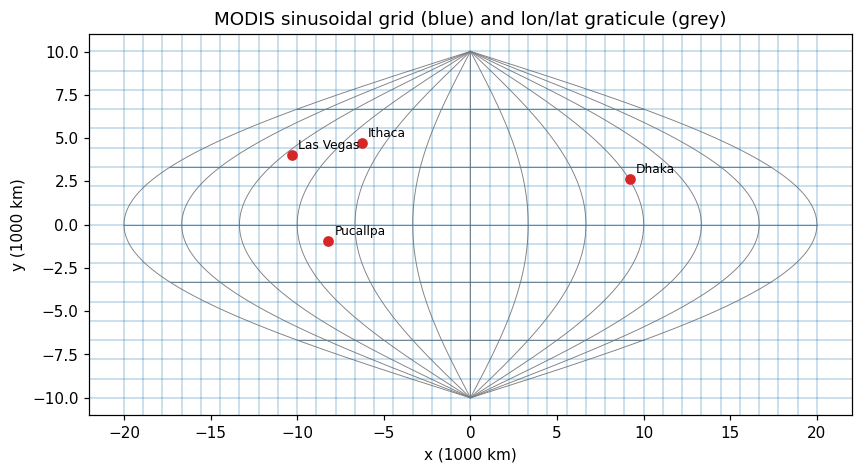

In [5]:
# The following code block visualizes how lines of constant longitude/latitude ("graticule") appear when projected
# into the MODIS sinusoidal projection, and overlays the MODIS tile grid. This shows the strong distortion/shear
# introduced by the projection, especially at high longitudes.

fig, ax = plt.subplots(figsize=(9, 4.5))  # Create a wide figure for the map

# Draw lines of constant longitude, sweeping through all latitudes.
for lon in range(-180, 181, 30):
    lat = np.linspace(-90, 90, 181)  # 181 steps from -90 to +90
    x, y = to_sin.transform(np.full_like(lat, lon), lat)  # Project into sinusoidal x/y
    ax.plot(np.array(x) / 1e6, np.array(y) / 1e6, color="grey", lw=0.6)  # Plot as thin grey line

# Draw lines of constant latitude, sweeping through all longitudes.
for lat in range(-90, 91, 30):
    lon = np.linspace(-180, 180, 361)  # 361 steps from -180 to +180
    x, y = to_sin.transform(lon, np.full_like(lon, lat))  # Project into sinusoidal x/y
    ax.plot(np.array(x) / 1e6, np.array(y) / 1e6, color="grey", lw=0.6)  # Plot as thin grey line

# Draw the MODIS tile grid as blue lines.
for k in range(37):
    # Vertical gridlines: shift by k in tile index, center is at h=18
    ax.axvline((k - 18) * TILE / 1e6, color="C0", lw=0.3)
for k in range(19):
    # Horizontal gridlines: v=9 is middle row
    ax.axhline((9 - k) * TILE / 1e6, color="C0", lw=0.3)

# Plot locations of a few example places as red markers with labels.
for p, ll in places.items():
    x, y = to_sin.transform(*ll)
    ax.plot(x / 1e6, y / 1e6, "o", color="C3")  # Plot the point
    ax.annotate(p.split(",")[0], (x / 1e6, y / 1e6),
                xytext=(4, 4), textcoords="offset points", fontsize=8)  # Add place name

# Set axis labels and plot title; set equal scaling; display the plot
ax.set(xlabel="x (1000 km)", ylabel="y (1000 km)", title="MODIS sinusoidal grid (blue) and lon/lat graticule (grey)")
ax.set_aspect("equal")
plt.show()

## Loading real MODIS data

`geolattice.rsense` has three ways to get real MODIS pixels, and this notebook ends up using all
three somewhere below:

1. **`geolattice.rsense.get_images`** — searches a STAC catalogue (Microsoft Planetary Computer, no
   account needed) and downloads just the bands you ask for as small, AOI-clipped GeoTIFFs.
   This is the route *Downloading a year of MODIS data* uses to build the whole 2024 time series analysed in the rest of
   this notebook.
2. **`rs.optical.load_modis`** — reads MOD09A1 (500 m) as a lazy, cloud-optimised cube with no
   files to manage; already scaled and cloud-masked. Needs the optional `odc-stac` package.
3. **NASA Earthdata (`earthaccess`)** — every MODIS product as HDF4 granules, which
   `rs.core.read_hdf` opens layer by layer. Needs a free Earthdata login.

The cell below tries routes 2 and 3 just to show the API, and reports clearly when an optional
package or login is missing rather than failing the notebook — that section's `get_images`
download needs neither.


In [6]:
# Define the area we want data for: here, Las Vegas valley, using its longitude and latitude bounds
AOI = (-115.45, 35.95, -114.85, 36.40)  # AOI = Area Of Interest

if ONLINE:  # If we have internet connection, try to download some sample MODIS data in 2 ways
    # First way: Try to use a function that fetches MODIS data in a ready-to-use format (needs a special package)
    try:
        mod_lazy = rs.optical.load_modis(AOI, ("2024-06-01", "2024-06-10"), mask=True)
        print(mod_lazy)  # Print a summary of what we got (an xarray object)
    except ImportError as exc:
        # If the needed package isn't installed, let the user know
        print("load_modis needs an optional dependency:", exc)

    # Second way: Get data directly from NASA's Earthdata archive, in HDF format (needs a free account)
    try:
        # Search for some data files (granules) from NASA Earthdata that match our area and dates
        granules = rs.access.earthdata_search("MOD13Q1", aoi=AOI, dates=("2024-06-01", "2024-06-30"))
        # Download the first file we found to a local folder
        files = rs.access.earthdata_download(granules[:1], "../../../../Data/08_remote_sensing/08_02_optical/modis")
        # Show what layers are inside that downloaded file
        print(rs.core.read_hdf(files[0]))  # This prints a dictionary of all the data layers
        # Read the NDVI (vegetation index) layer from the file
        ndvi = rs.core.read_hdf(files[0], "250m 16 days NDVI")
        # Fix the values using the right scale for this product
        ndvi = modis.scale_product(ndvi, "MOD13", "NDVI", fill=-3000)
    except Exception as exc:
        # If anything goes wrong (like missing login or package), tell the user that's why this part is skipped
        print("NASA Earthdata route skipped (needs earthaccess + a free login):", exc)
else:
    # If we don't have internet, just tell the user we're skipping this demo
    print("Offline: skipping the live demo routes. The download section needs internet to continue.")

load_modis needs an optional dependency: odc.stac is required; install with `pip install geolattice[rsense-access]`
NASA Earthdata route skipped (needs earthaccess + a free login): earthaccess is required; install with `pip install geolattice[rsense-access]`


## Downloading a year of MODIS data

`geolattice.rsense.get_images` searches Microsoft Planetary Computer and downloads MOD09Q1 — NASA's
8-day, 250 m surface reflectance composite — for the Las Vegas valley. Terra (`MOD`) and Aqua
(`MYD`) both publish this product; we keep Terra only, so composites fall 8 days apart just as
`rs.optical.load_modis` would return for MOD09A1. Only `red` and `nir` are measured at 250 m
(MOD09's other bands are 500 m or 1 km), which is enough for NDVI, QA decoding and the
resolution comparison in *MODIS versus Landsat: resolution and mixed pixels*.


In [7]:
# Read the Landsat image with its spectral bands, as labeled for common use
ls = rs.read(
    fetch("landsat_las_vegas.tif"),
    band_names=["coastal", "blue", "green", "red", "nir", "swir16", "swir22"]
)

# Mask out any invalid or non-positive reflectance values in the Landsat data
ls = ls.where(ls > 0)

# Derive a land cover classification for the area, using the first Landsat band as a template grid
landcover = nlcd_for(ls.isel(band=0))

# Print the shape/size of the Landsat data and the list of NLCD land cover classes present in the area
print(
    "Landsat:", dict(ls.sizes),
    "| NLCD classes present:", sorted(np.unique(landcover.values).tolist())
)

Landsat: {'band': 7, 'y': 729, 'x': 1166} | NLCD classes present: [11, 21, 22, 23, 24, 31, 41, 42, 43, 52, 71, 81, 90, 95]


In [8]:
# Search Planetary Computer for every MOD09Q1 composite over the AOI in 2024, then download
# red, nir and the state QA band as AOI-clipped GeoTIFFs with get_images.
# The item id encodes platform (MOD = Terra, MYD = Aqua) and acquisition day-of-year
# ("A2024129" = day 129 of 2024); keep Terra only, and the newest processing run per date
# (Planetary Computer sometimes carries two runs of the same granule).
OUT = DATA / "modis_2024"

# Let's fetch MODIS satellite images for our area of interest (Las Vegas valley) for the year 2024.
# We want NASA's Terra MODIS 8-day surface reflectance products ("MOD09Q1").
# Step 1: Search for available images ("items") in Microsoft's Planetary Computer
found = search_images(
    bbox=AOI,                             # The geographical area we're interested in
    dates=("2024-01-01", "2024-12-31"),   # We want all scenes in 2024
    source="planetary",                   # Search the Microsoft Planetary Computer
    collection="modis-09Q1-061",          # Specify the MODIS product version
    limit=150,                            # Don't return more than 150 results (plenty for 8-day in 1 yr)
    quiet=True,                           # Don't print progress messages
)

# Step 2: Of the found images, keep only the latest version for each 8-day period (sometimes there are duplicates)
latest = {}
for item in found.items:
    # Only consider Terra MODIS images for 2024 that have IDs like "MOD09Q1.A2024xxxx"
    if not item.id.startswith("MOD09Q1.A2024"):
        continue
    # Extract the date code (e.g. "A2024129" for day 129 of 2024)
    acq = item.id.split(".")[1]
    # Save the newest image for each date (sometimes there are two processing runs for the same day)
    if acq not in latest or item.id > latest[acq]:
        latest[acq] = item.id
# Gather the IDs, sorted in time order
terra_ids = sorted(latest.values())

# Step 3: Download the images!
# For each of these IDs, download the Red, NIR, and QA ("state") bands, clipped to our area of interest.
saved = get_images(
    OUT,                # The folder where to save images
    search=found,       # The search result object (so get_images can find the files)
    ids=terra_ids,      # The scene IDs to actually download
    bands=["red", "nir", "state"],   # Only get the needed bands (Red/NIR for NDVI + QA band)
    mode="clip",        # Crop images to exactly the AOI
    quiet=True,         # Hide extra output
)
print(saved)            # Print summary of what was downloaded and where

44 scene(s), 0 band file(s) to fetch, 132 already present



bands: 0it [00:00, ?it/s]


bands: 0it [00:00, ?it/s]

ImageResult(planetary/modis-09Q1-061, 44 scenes, 179 files, 0 failures, out=data/modis_2024)


In [9]:
# Assemble the downloaded scenes into one xarray.Dataset with the variable names MOD09
# products use. Two scene folders can share a date when the catalogue carries more than one
# processing run for a granule; sorting folders by name and keeping the last one per date keeps
# the newer run (its id, and so its folder name, sorts after the older one).


# We have a folder ("saved.out") that contains subfolders. Each subfolder is a "scene" (= one MODIS image for a date).
# Our goal: build a time series of MODIS images, stacking up Red, NIR, and "state" for each day we have.

# Step 1: For each scene subfolder, get its acquisition date, and keep only the latest for each date
by_date = {}
for scene_dir in sorted(p for p in saved.out.iterdir() if p.is_dir()):
    # The metadata about this image is stored in item.json. We read it in.
    item = json.loads((scene_dir / "item.json").read_text())
    # Use the "datetime" field (YYYY-MM-DD format, only the date part)
    date = item["properties"]["datetime"][:10]
    by_date[date] = scene_dir  # If there are several for same day, only the "latest" (sorted last) remains

# Step 2: Sort all the dates so they're in time order, then turn into pandas datetime objects
dates = pd.to_datetime(sorted(by_date))

# Step 3: For each date, collect the Red, NIR, and State images from the corresponding folder
red, nir, state = [], [], []
for day in dates:
    scene_dir = by_date[day.strftime("%Y-%m-%d")]
    # Read the "red" band from red.tif for this day. Take out the band dimension—it has only one band.
    red.append(rs.read(scene_dir / "red.tif").squeeze("band", drop=True))
    nir.append(rs.read(scene_dir / "nir.tif").squeeze("band", drop=True))
    # The state band is a little special—we don't mask it, just read as-is (QA info)
    state.append(rs.read(scene_dir / "state.tif", masked=False).squeeze("band", drop=True))

# Step 4: Stack up all the images in time
mod = xr.Dataset({
    "sur_refl_b01": xr.concat(red, dim="time"),   # Red band over time
    "sur_refl_b02": xr.concat(nir, dim="time"),   # NIR band over time
    # The state QA band, bit flags showing cloud/quality info. 250m, same as data bands.
    "sur_refl_state_500m": xr.concat(state, dim="time"),
}).assign_coords(time=("time", dates))

# Attach coordinate reference system info—use same as in red band (they all match)
mod = mod.rio.write_crs(red[0].rio.crs)

# Add an attribute clarifying that this is MODIS data
mod.attrs["geolattice.rsense:sensor"] = "modis"

# For convenience, get day-of-year values for each time slice, so we can plot by calendar later
doy = mod.time.dt.dayofyear.values

# Print out size info and time coverage
print("MODIS grid:", dict(mod.sizes), "| resolution:", round(abs(mod.rio.resolution()[0]), 2), "m")
print("Composites:", len(mod.time), "from", str(mod.time.values[0])[:10], "to", str(mod.time.values[-1])[:10])

# The dataset is ready! All further analysis works with "mod".
mod

MODIS grid: {'x': 489, 'y': 217, 'time': 44} | resolution: 231.66 m
Composites: 44 from 2024-01-01 to 2024-12-18


<xarray.Dataset> Size: 47MB
Dimensions:              (x: 489, y: 217, time: 44)
Coordinates:
  * x                    (x) float64 4kB -1.039e+07 -1.039e+07 ... -1.028e+07
  * y                    (y) float64 2kB 4.048e+06 4.047e+06 ... 3.998e+06
  * time                 (time) datetime64[ns] 352B 2024-01-01 ... 2024-12-18
    spatial_ref          int64 8B 0
Data variables:
    sur_refl_b01         (time, y, x) float32 19MB 1.096e+03 ... 1.708e+03
    sur_refl_b02         (time, y, x) float32 19MB 1.528e+03 ... 2.161e+03
    sur_refl_state_500m  (time, y, x) uint16 9MB 72 72 72 72 72 ... 72 72 72 72
Attributes:
    geolattice.rsense:sensor:  modis

In [10]:
# Let's assign each MODIS grid pixel a land cover group so we can compare NDVI by land type.
# We'll use the landcover raster, but first reproject it so it aligns (matches grid and size) with our MODIS data.
from rasterio.enums import Resampling

# Get a template--the spatial shape and transform--from the first time slice of MODIS red band.
tpl = mod["sur_refl_b01"].isel(time=0)

# Reproject the landcover raster ("lc") so its grid matches "tpl".
# "Resampling.mode" is used because landcover is categorical data (we want the most common value, not an average).
lc = landcover.rio.reproject_match(tpl, resampling=Resampling.mode)

# We'll make an array called "group" the same shape as the MODIS grid, starting with everything as "static".
group = np.full(lc.shape, "static", dtype=object)

# Now, classify pixels by their land cover code:
# Landcover values 31, 52, 71 represent desert/shrubland/grassland. We'll label as "desert".
group[np.isin(lc.values, [31, 52, 71])] = "desert"

# Landcover values 21, 22, 81, 82, 90, 95 are crops, pasture, and wetlands ("irrigated").
group[np.isin(lc.values, [21, 22, 81, 82, 90, 95])] = "irrigated"

# Landcover values 41, 42, 43 cover forests (deciduous, evergreen, mixed).
group[np.isin(lc.values, [41, 42, 43])] = "forest"

# Print the number of MODIS pixels for each group type (shows "desert", "irrigated", "forest", "static").
print("MODIS pixels per group:", {g: int((group == g).sum()) for g in ["desert", "irrigated", "forest", "static"]})

MODIS pixels per group: {'desert': 61138, 'irrigated': 3117, 'forest': 5740, 'static': 36118}


This is the real product: `sur_refl_b01`/`sur_refl_b02` are int16 digital numbers with MOD09's
fill value (`-28672`), and `sur_refl_state_500m` carries its real QA bit pattern (same layout as
the 500 m/1 km `state` layers, just at 250 m here). Nothing below is simulated — the sections from scale factors through the mixed-pixel comparison
run on these pixels exactly as downloaded, clouds and all.


## Scale factors and fill values

MODIS reflectance data is stored as 16-bit integer values called digital numbers (DN), which need to be converted to physically meaningful reflectance values.
The conversion is performed using a scale factor. For MODIS surface reflectance bands, the formula is:
**reflectance = DN × 0.0001**

Special values are used to indicate missing or invalid data. The value `-28672` is reserved as the "fill value," representing areas where data is missing or invalid.
Valid DN values for reflectance data typically range from −100 to 16,000. Values outside this range are generally considered invalid.

Different MODIS products and science datasets use their own scale factors depending on the measurement:
- Land Surface Temperature (LST): multiply DN by 0.02 to get Kelvin (DN × 0.02 K)
- Normalized Difference Vegetation Index (NDVI): DN × 0.0001
- Leaf Area Index (LAI): DN × 0.1
These scale factors and their corresponding offsets for various products and layers are collected in `modis.PRODUCT_SCALES`.

To automate this process, you can use `rs.optical.scale`, which:
- looks up the correct scale and offset for each band,
- masks out fill values (`-28672`) and out-of-range data,
- and leaves quality assurance (QA) layers untouched (since they aren't physically measured quantities).

Applying the proper scale and masking ensures that further analyses are done using real, physically-meaningful reflectance data instead of the raw integer codes.


In [11]:
# This line takes our MODIS satellite data and turns its raw numbers ("digital numbers" or DN) 
# into actual reflectance values (real physical meaning) using the built-in scaling rules.
refl = rs.optical.scale(mod)  # It figures out the sensor type from the band names automatically.

# These are the specific bands we care about: Band 1 (red) and Band 2 (near infrared) from the MOD09Q1 product.
bands = ["sur_refl_b01", "sur_refl_b02"]

# Let's pick the pixel that sits right in the middle of our image/time-stack for a quick check.
px = dict(
    time=len(mod.time) // 2,  # halfway through all the dates
    y=mod.sizes["y"] // 2,    # halfway down the image
    x=mod.sizes["x"] // 2     # halfway across the image
)

# Now, we're making a little table for those two bands showing:
# - the original DN value (raw MODIS output)
# - and the reflectance, which is DN scaled properly (actual reflectance, between e.g. 0 and 1)
pd.DataFrame({
    "DN": [int(mod[b].isel(px)) for b in bands],
    "reflectance": [round(float(refl[b].isel(px)), 4) for b in bands]
}, index=bands)

,DN,reflectance
sur_refl_b01,2272,0.2272
sur_refl_b02,2486,0.2486


In [12]:
pd.DataFrame([(p, layer, s, o) for p, d in modis.PRODUCT_SCALES.items() for layer, (s, o) in d.items()],
             columns=["Product", "Layer", "Scale", "Offset"])

,Product,Layer,Scale,Offset
0,MOD09,sur_refl,0.0001,0.00
1,MOD13,NDVI,0.0001,0.00
2,MOD13,EVI,0.0001,0.00
3,MOD11,LST_Day_1km,0.0200,0.00
4,MOD11,LST_Night_1km,0.0200,0.00
5,MOD11,Emis_31,0.0020,0.49
6,MOD11,Emis_32,0.0020,0.49
7,MOD15,Lai_500m,0.1000,0.00
8,MOD15,Fpar_500m,0.0100,0.00
9,MOD17,Gpp_500m,0.0001,0.00


In [13]:
# Let's see how to convert raw MODIS numbers into real temperatures:
# Imagine you get a list of numbers from the satellite—these aren't temperatures yet, they're just "codes" (called DNs).
# For MODIS LST (Land Surface Temperature) from the MOD11 product, you turn the code into degrees Kelvin by multiplying by 0.02.
# We'll make a fake list of 4 pixel values. One of them (0) is actually a special value that means "no data" and should become "NaN" (not a number).
lst_dn = xr.DataArray(np.array([0, 14800, 15250, 16000]), dims="pixel")
# This line magically converts those codes into real temperatures (in Kelvin) for each pixel.
print("LST (K):", modis.scale_product(lst_dn, "MOD11", "LST_Day_1km").values)   # 0 is fill → NaN

LST (K): [ nan 296. 305. 320.]


## Decoding QA bits and masking clouds

MODIS surface reflectance quality (QA) information is stored compactly within the bits of the `sur_refl_state_500m` integer array. Each bit or set of bits encodes whether specific pixel conditions like cloud, shadow, or snow are present.

Detailed breakdown for the MOD09 `state_500m` QA band:

| Bit Positions | Field Name                  | Encoded Values (as bits and meaning)                                 |
|--------------|-----------------------------|---------------------------------------------------------------------|
| 0-1          | Cloud state                 | 00: clear, 01: cloudy, 10: mixed, 11: not set                       |
| 2            | Cloud shadow                | 0: no shadow, 1: shadow present                                     |
| 8-9          | Cirrus                      | 00: none, 01: small, 10: average, 11: high cirrus presence          |
| 10           | Internal cloud algorithm     | 0: cloud not detected, 1: cloud detected by internal cloud algorithm|
| 13           | Adjacent to cloud           | 0: no, 1: adjacent to cloud                                         |
| 15           | Internal snow mask          | 0: not snow, 1: snow present                                        |

This organization allows efficient storage and extraction of QA features. To interpret the bits:
- You can extract any of these fields from the QA layer by using: `rs.optical.decode_bits(qa, start, length)`,
  where `start` is the starting bit position and `length` is the number of bits in the field.
  For instance, to obtain the cloud state for all pixels: `rs.optical.decode_bits(qa, 0, 2)`.
- For common masking tasks (e.g., isolating high-quality, "usable" pixels), the convenience function
  `modis_state_mask` combines tests for cloud, shadow, and other relevant bits into a single boolean mask.
  This mask can then be used to remove problematic pixels from further analysis.


In [14]:
# Extract the QA (Quality Assurance) layer for a single time step (here, the 4th composite, since Python uses zero-based indexing).
qa = mod["sur_refl_state_500m"].isel(time=3)

# Decode selected QA bit fields for every pixel:
# - cloud_state: uses bits 0-1 (2 bits) to indicate clear, cloudy, mixed, etc.
# - shadow: uses bit 2 to indicate whether cloud shadow is present.
# - internal_cloud: uses bit 10 to indicate if MODIS' internal cloud algorithm marks the pixel as cloudy.
fields = pd.DataFrame({
    "cloud_state": rs.optical.decode_bits(qa, 0, 2).values.ravel(),
    "shadow": rs.optical.decode_bits(qa, 2).values.ravel(),
    "internal_cloud": rs.optical.decode_bits(qa, 10).values.ravel(),
})

# Count all unique combinations of these QA classes to see how many pixels fall into each category.
fields.value_counts().rename("pixels").reset_index()

,cloud_state,shadow,internal_cloud,pixels
0,0,0,0,83189
1,1,0,0,6620
2,2,0,0,5520
3,0,0,1,5116
4,0,1,0,2452
5,2,0,1,1930
6,1,0,1,838
7,2,1,0,316
8,1,1,0,132


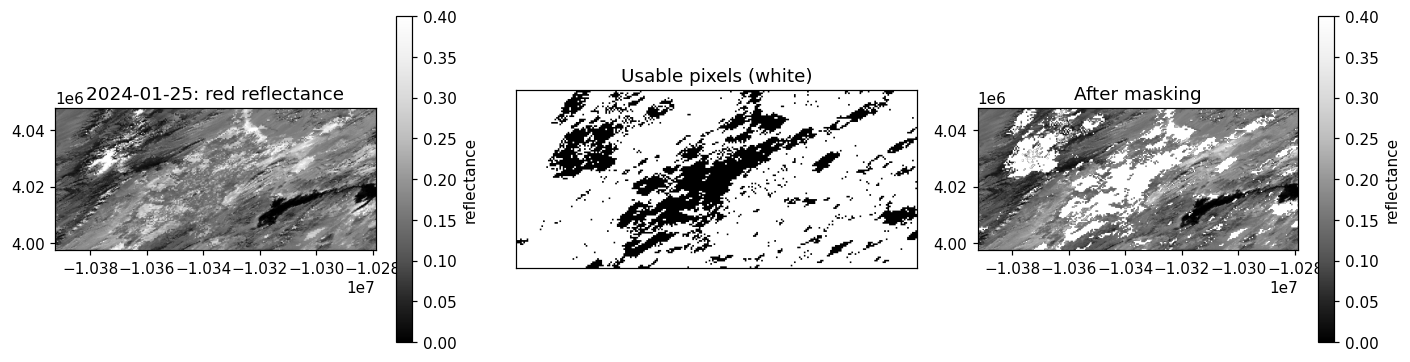

In [15]:
# The following code demonstrates how to apply pixel-quality masking to MODIS reflectance data and visualize the result.

# 1. Generate a boolean mask (`valid`) indicating "usable" pixels according to the MODIS QA (quality assurance) bits—
#    clouds, shadows, etc.—with True meaning good data.
valid = rs.optical.modis_state_mask(mod["sur_refl_state_500m"])

# 2. Mask out problematic pixels (clouds/shadows) in all reflectance bands using the above mask.
#    `clean` is the reflectance dataset with unusable pixels set to NaN.
clean = rs.optical.mask_clouds(refl, drop_qa=True)  # Equivalent to refl.where(valid) for every band

# 3. Visualize (a) the original reflectance, (b) the cloud mask, and (c) the masked result for one 8-day composite:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
k = 3  # Select the 4th composite by index

# (a) Plot red band reflectance before masking
rs.viz.plot_raster(
    refl["sur_refl_b01"].isel(time=k),
    ax=axes[0], cmap="Greys_r", vmin=0, vmax=0.4,
    title=f"{str(mod.time.values[k])[:10]}: red reflectance"
)

# (b) Visualize the cloud/shadow/quality mask ("usable" pixels are white)
axes[1].imshow(valid.isel(time=k), cmap="gray")
axes[1].set_title("Usable pixels (white)")

# (c) Plot red reflectance after cloud/shadow masking
rs.viz.plot_raster(
    clean["sur_refl_b01"].isel(time=k),
    ax=axes[2], cmap="Greys_r", vmin=0, vmax=0.4,
    title="After masking"
)

# Remove ticks from the mask and masked images for clearer visualization
for a in axes[1:2]:
    a.set_xticks([])
    a.set_yticks([])

plt.tight_layout()
plt.show()

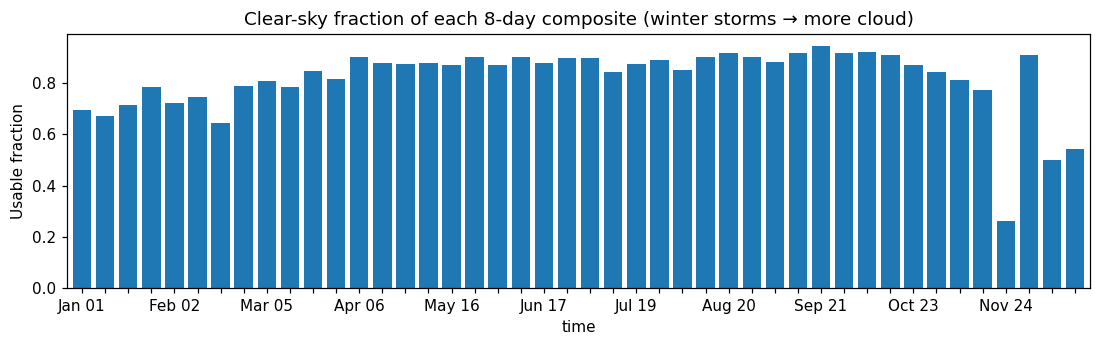

In [16]:
# This code calculates and plots the fraction of "usable" (clear-sky, not cloudy) pixels for each MODIS 8-day composite.
# 1. Compute the mean of the 'valid' mask across spatial dimensions ('y', 'x') for each time step,
#    resulting in the proportion of usable pixels in each 8-day composite.
frac = valid.mean(("y", "x")).to_series()

# 2. Plot these usable fractions as a bar chart, showing the clear-sky fraction over time.
ax = frac.plot(kind="bar", figsize=(12, 3), color="C0", width=0.8)

# 3. Format the x-axis labels to display the date every 4th bar for better readability.
ax.set_xticklabels(
    [d.strftime("%b %d") if i % 4 == 0 else "" for i, d in enumerate(frac.index)],
    rotation=0
)

# 4. Add labels and a title to make the plot informative.
ax.set(
    ylabel="Usable fraction",
    title="Clear-sky fraction of each 8-day composite (winter storms → more cloud)"
)

# 5. Display the plot.
plt.show()

## Vegetation index time series and maximum-value composites

`clean.rs.index(...)` computes indices using canonical band names; `geolattice.rsense` maps
`sur_refl_b01` → red, `sur_refl_b02` → NIR and so on automatically. We summarise NDVI by
land-cover group to see the distinct seasonal signatures.


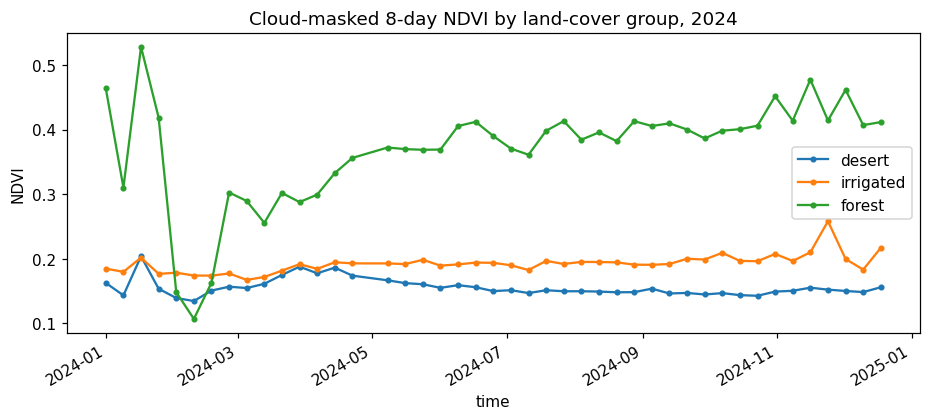

In [17]:
# Compute NDVI from the cloud-masked MODIS data using canonical band names.
# Note: EVI requires a blue band, but at 250 m resolution only red and NIR are available.
vi = clean.rs.index(["NDVI"])

# Map each pixel to a string label for its group (e.g., "desert", "irrigated", "forest")
groups = xr.DataArray(
    group.astype(str),
    dims=("y", "x"),
    coords={"y": vi.y, "x": vi.x}
)

# For each group, calculate the mean NDVI over all pixels in that group for each time step,
# producing a time series of mean NDVI for each land-cover type.
profiles = pd.DataFrame({
    g: vi["NDVI"].where(groups == g).mean(("y", "x")).to_series()
    for g in ["desert", "irrigated", "forest"]
})

# Plot the NDVI time series for each group, marking each point and applying axis labels and title
ax = profiles.plot(figsize=(10, 4), marker="o", ms=3)
ax.set(
    ylabel="NDVI",
    title="Cloud-masked 8-day NDVI by land-cover group, 2024"
)
plt.show()

MOD13 vegetation-index products reduce cloud and view-angle effects further by keeping the
*maximum* NDVI in each 16-day window (the maximum-value composite, MVC). Clouds lower NDVI,
so the maximum is usually the clearest observation.


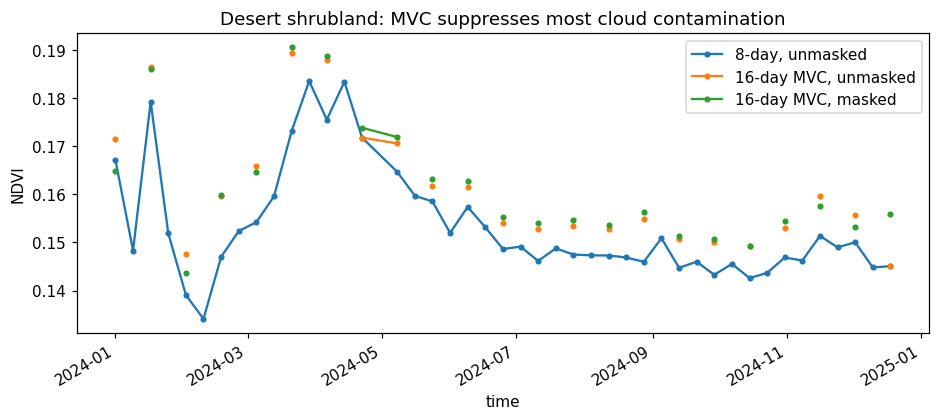

In [18]:
# Compute NDVI from the original reflectance data WITHOUT cloud-masking, for comparison.
ndvi_raw = refl.rs.index("NDVI")  # Not cloud-masked; illustrates effect of MVC

# Compute the 16-day maximum-value composite (MVC) for the unmasked NDVI—
# this means, for each 16-day period, keep the highest observed NDVI per pixel (to minimize cloud impact).
mvc = ndvi_raw.resample(time="16D").max()

# Do the same 16-day MVC, but on the already cloud-masked NDVI (vi["NDVI"]).
mvc_masked = vi["NDVI"].resample(time="16D").max()

# Pick a single group/landcover type ("desert") for plotting.
g = "desert"

# Prepare a DataFrame with three series for "desert" pixels:
#   1. 8-day mean NDVI, from unmasked data (shows full noise/clouds),
#   2. 16-day MVC mean NDVI, from unmasked data (shows how MVC removes noise),
#   3. 16-day MVC mean NDVI, from masked data (shows best case, after masking + MVC).
plot_data = pd.DataFrame({
    "8-day, unmasked": ndvi_raw.where(groups == g).mean(("y", "x")).to_series(),
    "16-day MVC, unmasked": mvc.where(groups == g).mean(("y", "x")).to_series(),
    "16-day MVC, masked": mvc_masked.where(groups == g).mean(("y", "x")).to_series(),
})

# Plot the three time series to compare the cloud reduction effects, with appropriate labels and a title.
plot_data.plot(figsize=(10, 4), marker=".", title="Desert shrubland: MVC suppresses most cloud contamination")
plt.ylabel("NDVI")
plt.show()

## Smoothing and land surface phenology

Even after masking, gaps and residual noise remain. The Whittaker smoother
(`rs.timeseries.whittaker`) fills gaps and smooths the series in one linear solve for all
pixels. `rs.timeseries.phenology` then extracts the start (SOS), peak (POS) and end (EOS) of
season and the amplitude, using the amplitude-threshold method popularised by TIMESAT.


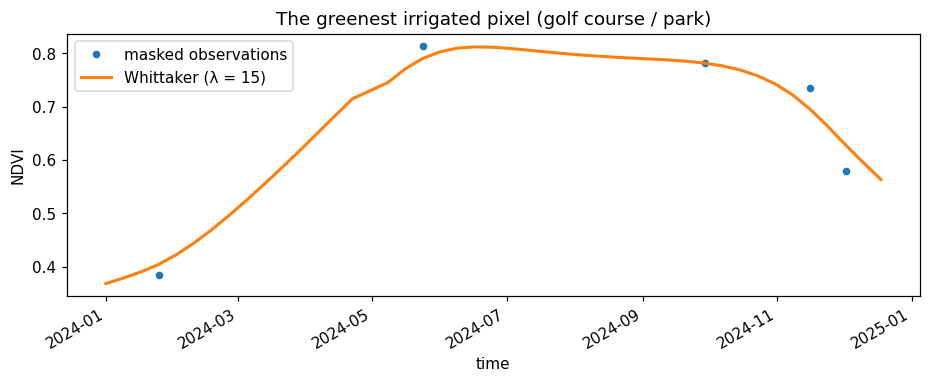

In [19]:
# Apply the Whittaker smoother to the cloud-masked NDVI time series to fill gaps and reduce noise.
smooth = rs.timeseries.whittaker(vi["NDVI"], lmbda=15)

# Identify a particularly 'green' (high NDVI) irrigated pixel for demonstration.
# 1. Compute NDVI for the Landsat image, and reproject it to match the MODIS grid.
ls_ndvi = rs.optical.index(ls.to_dataset(dim="band"), "NDVI")
ndvi_j = ls_ndvi.rio.reproject_match(tpl, resampling=Resampling.average).values

# 2. Among all pixels labeled as "irrigated", find the one with the highest NDVI value.
i, j = np.unravel_index(
    np.nanargmax(np.where(group == "irrigated", ndvi_j, np.nan)),
    group.shape
)

# Extract the NDVI time series for the chosen pixel, both raw and smoothed.
s_raw = vi["NDVI"].isel(y=i, x=j).to_series()
s_sm = smooth.isel(y=i, x=j).to_series()

# Plot both the masked observations (raw) and the Whittaker-smoothed time series
# for this pixel, illustrating the effect of the smoother.
ax = s_raw.plot(style="o", ms=4, label="masked observations", figsize=(10, 3.5))
s_sm.plot(ax=ax, lw=2, label="Whittaker (λ = 15)")
ax.set(
    ylabel="NDVI", 
    title="The greenest irrigated pixel (golf course / park)"
)
ax.legend()
plt.show()

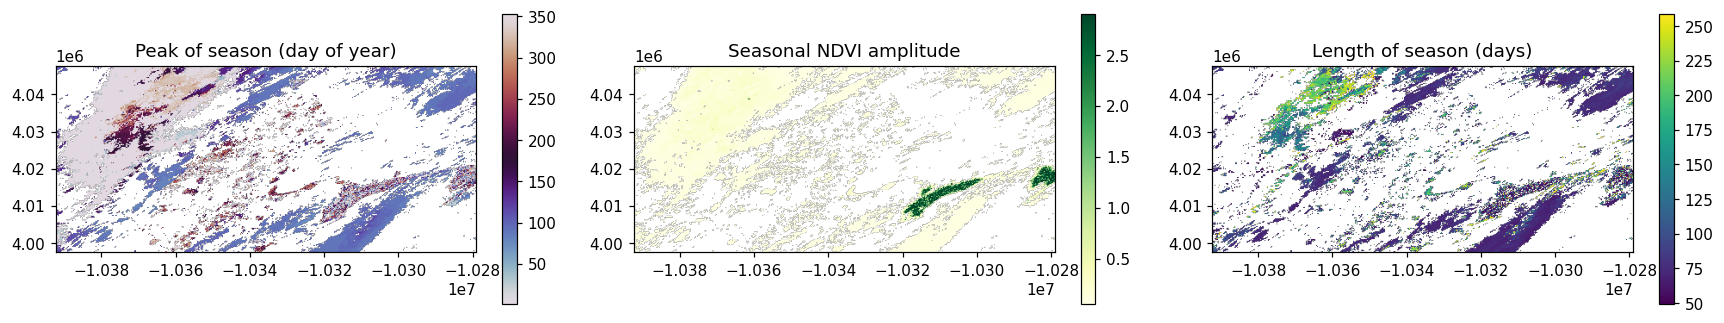

In [20]:
# Extract phenological metrics from the smoothed NDVI time series using the amplitude-threshold method.
# - threshold=0.5 means SOS/POS/EOS are defined at 50% of the seasonal amplitude.
# - min_amplitude=0.05 filters out pixels with low seasonal variability (likely noise).
pheno = rs.timeseries.phenology(smooth, threshold=0.5, min_amplitude=0.05)

# Create a figure with 3 horizontal subplots to visualize key phenological maps.
fig, axes = plt.subplots(1, 3, figsize=(16, 3.6))

# Plot the peak of season (POS, as day-of-year) using a cyclic colormap to highlight the timing.
rs.viz.plot_raster(pheno["pos"], ax=axes[0], cmap="twilight", title="Peak of season (day of year)")

# Plot the NDVI seasonal amplitude (difference between max/min NDVI) to show the strength of vegetation cycles.
rs.viz.plot_raster(pheno["amplitude"], ax=axes[1], cmap="YlGn", title="Seasonal NDVI amplitude")

# Plot the length of season (LOS, duration of the green season) using a sequential colormap.
rs.viz.plot_raster(pheno["los"], ax=axes[2], cmap="viridis", title="Length of season (days)")

# Adjust spacing and render all three plots.
plt.tight_layout()
plt.show()

In [21]:
# This code summarizes key phenological metrics (start of season [sos], peak of season [pos], end of season [eos], and seasonal amplitude)
# for each land cover group ("desert", "irrigated", "forest").
# 
# - For each metric in ["sos", "pos", "eos", "amplitude"], it flattens the metric's array values and the group label array.
# - It then groups the metric's values by their associated land cover type and computes the median for each group.
# - These median values are collected into a DataFrame, from which only the rows for "desert", "irrigated", and "forest" are selected.
# - Finally, the table is rounded to two decimal places and shown as a concise summary.
summary = pd.DataFrame({
    k: pd.Series(pheno[k].values.ravel())
        .groupby(group.ravel()).median()
    for k in ["sos", "pos", "eos", "amplitude"]
}).loc[["desert", "irrigated", "forest"]]
summary.round(2)

,sos,pos,eos,amplitude
desert,62.060001,89.0,136.779999,0.07
irrigated,140.830002,241.0,300.260010,0.09
forest,133.279999,9.0,37.730000,0.15


On real pixels, desert shrubland and irrigated turf show sensible seasons: desert peaks around
day 90 (late March), well before summer heat and drought, and senesces by mid-May; irrigated
turf and parks green later and hold a long season, consistent with year-round watering. The
small forest sample (5,740 pixels on the Spring Mountains) is noisier — a single imperfectly
masked composite in early January can outscore every true summer value, pulling the
amplitude-threshold "peak" into winter. That is the real-data lesson a synthetic series hides:
QA masking removes most, not all, contamination, and a method built on one global maximum is
not robust to a single bad date in a short series. Exercise 2 asks you to fix it.


## MODIS versus Landsat: resolution and mixed pixels

MOD09Q1's "250 m" grid cell is actually 231.656 m on a side — about 6.6 Landsat 90 m pixels, or
roughly 60 Landsat 30 m pixels, per MODIS cell. Where land cover changes over short distances —
the edge of a city, a golf course, a canyon — the MODIS value is a mixture. We reproject the
MODIS composite closest to the Landsat scene's acquisition date (8 July 2024) to UTM and
compare it with Landsat NDVI.


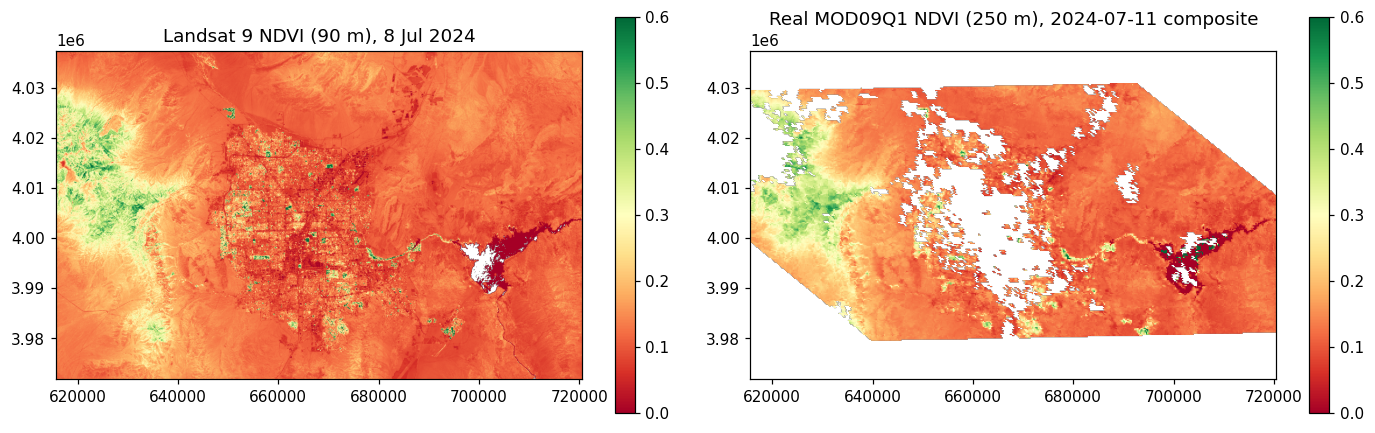

In [22]:
# This code compares the spatial resolution and appearance of NDVI (Normalized Difference Vegetation Index) from Landsat 9 (high spatial resolution, 90 m) and MODIS MOD09Q1 (coarser spatial resolution, 250 m) on a date close to July 8, 2024.
# 
# 1. Find the MODIS composite date closest to Julian day 190 (approximately July 8):
k = int(np.argmin(np.abs(doy - 190)))

# 2. Select the NDVI data from MODIS for that date, assign it its native sinusoidal projection, then reproject to match the Landsat UTM projection (with MODIS native pixel size):
mod_utm = vi["NDVI"].isel(time=k).rio.write_crs(SIN).rio.reproject(ls.rio.crs, resolution=231.656358)

# 3. Compute NDVI from the Landsat image (using reflectance for red and NIR bands):
ls_ndvi = rs.optical.index(ls.to_dataset(dim="band"), "NDVI")

# 4. Create a side-by-side plot comparing the two products, using the same NDVI color scale:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
rs.viz.plot_raster(ls_ndvi, ax=axes[0], cmap="RdYlGn", vmin=0, vmax=0.6, title="Landsat 9 NDVI (90 m), 8 Jul 2024")
rs.viz.plot_raster(mod_utm, ax=axes[1], cmap="RdYlGn", vmin=0, vmax=0.6,
                   title=f"Real MOD09Q1 NDVI (250 m), {str(mod.time.values[k])[:10]} composite")

# 5. Set identical axis extents for both panels so they cover the same spatial area:
for a in axes:
    a.set_xlim(float(ls.x.min()), float(ls.x.max()))
    a.set_ylim(float(ls.y.min()), float(ls.y.max()))

# 6. Adjust layout and display:
plt.tight_layout()
plt.show()

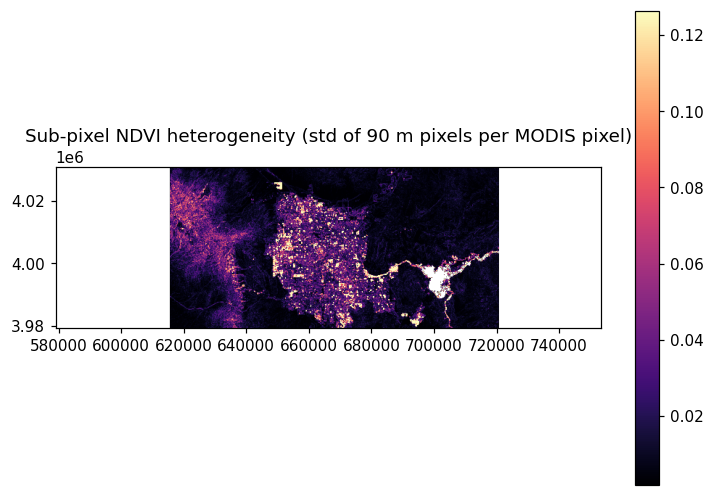

MODIS pixels with sub-pixel NDVI std > 0.1: 1.7%


In [23]:
# This code quantifies how much variability exists within each MODIS (250 m) pixel by examining the spread (standard deviation) of Landsat NDVI (90 m) pixels that fall inside it:
# 1. Use `rs.fusion.upscale` to aggregate (upscale) the high-resolution Landsat NDVI values (ensuring correct CRS and naming) onto the MODIS pixel grid, calculating the standard deviation for each MODIS pixel area.
het = rs.fusion.upscale(ls_ndvi.rio.write_crs(ls.rio.crs).rename("ndvi"), mod_utm, method="std")

# 2. Visualize the resulting heterogeneity (per-MODIS-pixel NDVI standard deviation) as an image using a perceptual colormap for contrast.
ax = rs.viz.plot_raster(het, cmap="magma", title="Sub-pixel NDVI heterogeneity (std of 90 m pixels per MODIS pixel)")
plt.show()

# 3. Print the proportion of MODIS pixels for which the sub-pixel Landsat NDVI standard deviation exceeds 0.1 (indicating significant heterogeneity/mixing within those coarse pixels).
print(f"MODIS pixels with sub-pixel NDVI std > 0.1: {float((het > 0.1).mean()):.1%}")

Heterogeneity concentrates along the urban fringe, parks and the mountains — exactly where MODIS
values must be interpreted as mixtures. Module 21 (fusion) shows how STARFM combines MODIS's
frequency with Landsat's detail.


## Bangladesh NDWI, 2020

A country-scale, full-year example that uses every technique from this module at once:
Bangladesh straddles **two** MODIS tiles, so every date needs mosaicking before it is useful.
We download a real year of MOD13Q1, mask by pixel quality, mosaic the two tiles, reproject from
the sinusoidal grid to Bangladesh's own projected system (BUTM), clip to the national boundary,
compute a water index, animate the whole year, and save the result as Zarr.

**Why not NDWI from MOD09Q1?** The 250 m product in *Downloading a year of MODIS data* only measures red and NIR; McFeeters'
NDWI needs a green band, which MODIS only carries at 500 m and coarser. MOD13Q1 (250 m, 16-day)
instead republishes NIR alongside a mid-infrared (MIR, ~2.1 µm, i.e. SWIR) band — enough for the
NIR/SWIR water index of Xiao et al. (2002), the formulation most MODIS flood and surface-water
studies actually use (`geolattice.rsense` implements this formula as `NDMI`, aliased `LSWI`). Unlike
McFeeters' version it also responds to vegetation canopy water, so values above roughly 0.3-0.4
usually mean open water or flooded vegetation, not just "wet ground" — worth keeping in mind
when reading the map below.


In [ ]:
# This block reads the Bangladesh national boundary shapefile, transforms it to WGS84 (latitude/longitude),
# and determines the bounding box of the country in lon/lat coordinates. It prints out how many boundary features
# were loaded, the CRS information, and the bounding box coordinates. 
# It then checks which MODIS tile *each* corner of the bounding box falls into, printing the result for 
# both the northwest and southeast corners, highlighting why a mosaic of multiple MODIS tiles is necessary.

import geopandas as gpd

# Read the Bangladesh boundary shapefile in its local (BUTM) projection
bd = gpd.read_file("../../../../Data/00_shared/data_geostatistics/BD_Banladesh_BUTM.shp")

# Reproject the boundary to WGS84 (EPSG:4326, standard lat/lon)
bd_ll = bd.to_crs(4326)

# Extract the bounding box as (minlon, minlat, maxlon, maxlat)
BD_BBOX = tuple(float(v) for v in bd_ll.total_bounds)

# Print summary information
print(f"{len(bd)} boundary features | CRS: {bd.crs.name}")
print("bbox (lon/lat):", tuple(round(v, 3) for v in BD_BBOX))

# Check which MODIS tiles the bounding box's corners fall into
corners = {"Northwest": (BD_BBOX[0], BD_BBOX[3]), "Southeast": (BD_BBOX[2], BD_BBOX[1])}
for name, (lon, lat) in corners.items():
    print(f"{name} corner -> {modis_tile(lon, lat)[0]}")

Bangladesh spans MODIS tiles **h25v06** (a sliver in the northwest) and **h26v06** (almost
everything else). `get_images` downloads every tile that intersects the bounding box, so one
search already returns both — we just need to mosaic them per date rather than collapse them.


In [ ]:
# This block searches for MOD13Q1 (Terra) MODIS surface reflectance composites over Bangladesh for the year 2020,
# retrieves their metadata, and downloads relevant bands. 
# Here's what each part does:

# 1. Set the output directory for the data.
OUT_BD = DATA / "modis13_bangladesh_2020"

# 2. Use the search_images function to find all MODIS MOD13Q1 scenes over the Bangladesh bounding box (BD_BBOX)
#    within the 2020 calendar year, querying the Planetary Computer collection for MOD13Q1 version 6.1 data.
#    The limit parameter controls the maximum number of returned results; quiet suppresses verbose output.
found_bd = search_images(
    bbox=BD_BBOX, 
    dates=("2020-01-01", "2020-12-31"),
    source="planetary", 
    collection="modis-13Q1-061", 
    limit=200, 
    quiet=True,
)

# 3. Build a dictionary to keep track of the latest available scene for each unique combination of
#    acquisition day (acq) and MODIS tile. This ensures that if there were multiple processing
#    runs for a given date/tile, only the most recent is kept (prevents duplicate runs).
latest_bd = {}
for item in found_bd.items:
    if not item.id.startswith("MOD13Q1.A2020"):
        continue  # Only process images from the year 2020
    _, acq, tile, _, _ = item.id.split(".")  # Extract acquisition day and tile
    key = (acq, tile)
    # Keep the newest processing run for each (acq, tile)
    if key not in latest_bd or item.id > latest_bd[key]:
        latest_bd[key] = item.id
# Create a sorted list of dataset ids to fetch.
bd_ids = sorted(latest_bd.values())

# 4. Download and clip the required images. get_images fetches the images referenced by bd_ids,
#    saving them under OUT_BD. It specifically requests the NIR, MIR, and quality bands for each item,
#    and clips each to the bounding box. The mode 'clip' restricts downloads to the area of interest.
saved_bd = get_images(
    OUT_BD, 
    search=found_bd, 
    ids=bd_ids,
    bands=["nir", "mir", "quality"], 
    mode="clip", 
    quiet=True,
)

# 5. Print summary information about what was downloaded.
print(saved_bd)

46 scene(s), 0 band file(s) to fetch, 138 already present



bands: 0it [00:00, ?it/s]


bands: 0it [00:00, ?it/s]

ImageResult(planetary/modis-13Q1-061, 46 scenes, 187 files, 0 failures, out=data/modis13_bangladesh_2020)


For each date: mosaic the (up to two) tiles, reproject the reflectance bands to the BUTM grid,
reproject the categorical QA band separately with nearest-neighbour resampling (bilinear would
corrupt its bit flags), clip both to the real national boundary, mask by pixel quality, then
compute the NIR/SWIR water index.


In [ ]:
# --- Explanation of Code Processing MODIS NDWI Composites for Bangladesh 2020 ---

# 1. Organize downloaded MODIS scenes by acquisition date.
by_date_bd = {}
for scene_dir in sorted(p for p in saved_bd.out.iterdir() if p.is_dir()):
    # Each folder represents a MODIS scene. Load its JSON metadata.
    item = json.loads((scene_dir / "item.json").read_text())
    # Group all scene directories by their acquisition date (YYYY-MM-DD). 
    by_date_bd.setdefault(item["properties"]["datetime"][:10], []).append(scene_dir)

# 2. For each acquisition date, process that day's available tiles.
ndwi_frames, valid_frames = [], []
for day in sorted(by_date_bd):
    tiles = by_date_bd[day]  # This is typically 1 or 2 (for Bangladesh, which spans two MODIS tiles).

    # a. Mosaic all tiles for this date for each band (nir, mir, quality).
    nir_m = rs.mosaic([rs.read(d / "nir.tif").squeeze("band", drop=True) for d in tiles])
    mir_m = rs.mosaic([rs.read(d / "mir.tif").squeeze("band", drop=True) for d in tiles])
    qa_m  = rs.mosaic([rs.read(d / "quality.tif", masked=False).squeeze("band", drop=True) for d in tiles])

    # b. Reproject the reflectance bands (nir, mir) to the Bangladesh grid using bilinear interpolation for continuous values.
    refl = rs.reproject(xr.Dataset({"nir": nir_m, "mir": mir_m}), bd.crs,
                        resolution=231.656358, resampling="bilinear")
    # c. Reproject the categorical quality band using nearest-neighbor (to preserve bitfield semantics).
    qa_r = qa_m.rio.write_crs(nir_m.rio.crs).rio.reproject_match(refl["nir"], resampling=Resampling.nearest)

    # d. Clip both the reflectance and quality bands to the actual Bangladesh boundary.
    refl_c, qa_c = rs.clip(refl, bd), rs.clip(qa_r, bd)

    # e. Generate a mask of good/marginal quality pixels (MODIS VI usefulness flags 0 or 1).
    valid = rs.optical.modis_vi_mask(qa_c, max_level=1)  # Only keep high/marginal usability

    # f. Apply MOD13 fill values and scaling: ignore original fill values (-1000), scale by 0.0001.
    nir_s = refl_c["nir"].where(refl_c["nir"] != -1000) * 1e-4
    mir_s = refl_c["mir"].where(refl_c["mir"] != -1000) * 1e-4

    # g. Calculate NDWI (Normalized Difference Water Index) for all valid pixels and save the mask.
    ndwi = ((nir_s - mir_s) / (nir_s + mir_s)).where(valid)
    ndwi_frames.append(ndwi)
    valid_frames.append(valid)

# 3. Stack the NDWI and validity masks along the time dimension (aligned with MODIS composite midpoint dates).
time_bd = pd.DatetimeIndex(sorted(by_date_bd)).rename("time")
bd_ds = xr.Dataset({
    "ndwi": xr.concat(ndwi_frames, dim=time_bd),
    "valid": xr.concat(valid_frames, dim=time_bd),
}).rio.write_crs(bd.crs)

print("Composites:", bd_ds.sizes["time"], "| grid:", dict(bd_ds.sizes))
bd_ds   # The resulting dataset: NDWI time series for all valid pixels in Bangladesh for 2020.

Composites: 23 | grid: {'x': 2070, 'y': 2890, 'time': 23}


<xarray.Dataset> Size: 688MB
Dimensions:      (x: 2070, y: 2890, time: 23)
Coordinates:
  * x            (x) float64 17kB 2.986e+05 2.989e+05 ... 7.777e+05 7.779e+05
  * y            (y) float64 23kB 2.947e+06 2.947e+06 ... 2.278e+06 2.277e+06
  * time         (time) datetime64[ns] 184B 2020-01-01 2020-01-17 ... 2020-12-18
    spatial_ref  int64 8B 0
Data variables:
    ndwi         (time, y, x) float32 550MB nan nan nan nan ... nan nan nan nan
    valid        (time, y, x) bool 138MB False False False ... False False False

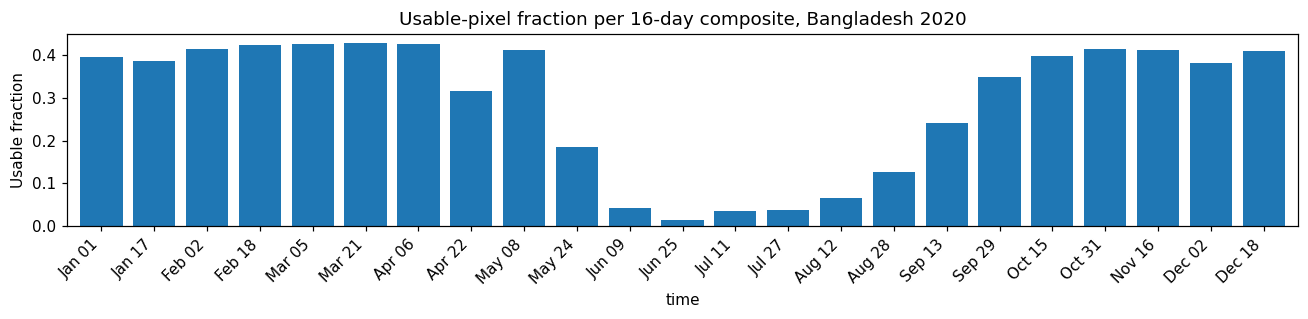

In [27]:
frac_bd = bd_ds["valid"].mean(("y", "x")).to_series()
ax = frac_bd.plot(kind="bar", figsize=(12, 3), color="C0", width=0.8)
ax.set_xticklabels([d.strftime("%b %d") for d in frac_bd.index], rotation=45, ha="right")
ax.set(ylabel="Usable fraction", title="Usable-pixel fraction per 16-day composite, Bangladesh 2020")
plt.tight_layout(); plt.show()

The country is barely visible from June to August: the usable fraction drops from ~40% in the
dry season to **1-7%** across the monsoon, with a low of 1.4% on 25 June. This is the central
limitation of optical satellites for flood monitoring in Bangladesh — clouds hide the water
exactly when floods happen, which is why operational flood mapping here leans on Sentinel-1
radar instead, which sees straight through cloud.


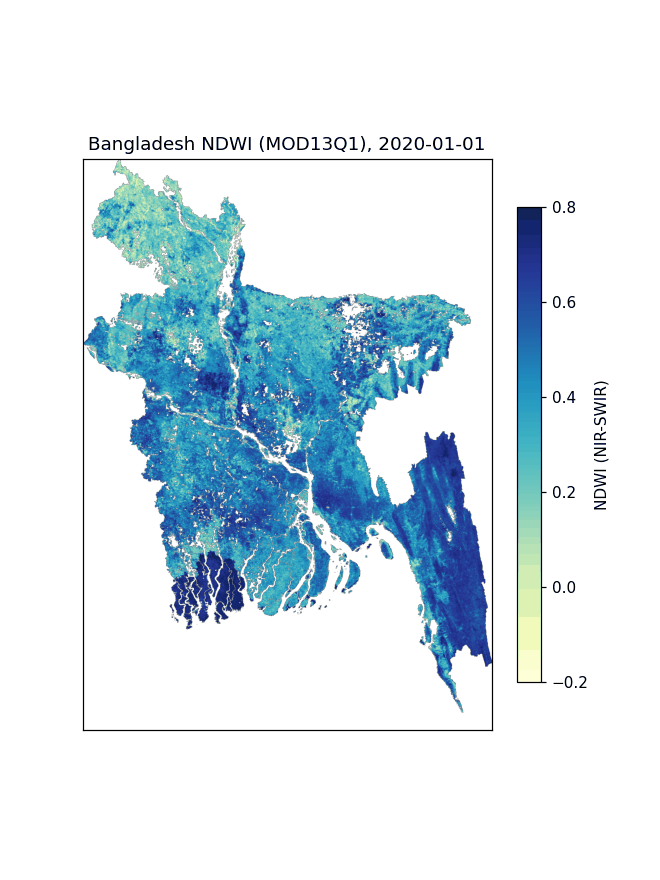

In [ ]:
# This section creates an animation (GIF) showing how the NDWI (Normalized Difference Water Index)
# varies across Bangladesh over the year 2020 using the MODIS time series data.

import matplotlib.animation as animation
from IPython.display import Image as IPImage

# 1. Set up an output directory for saving the animation
OUT_DIR = Path("outputs")
OUT_DIR.mkdir(exist_ok=True)

# 2. Compute NDWI values as a dense (in-memory) array for all time steps
ndwi_vals = bd_ds["ndwi"].compute()

# 3. Create the figure and axis for the animation, display the first time slice initially.
fig, ax = plt.subplots(figsize=(6, 8))
im = ax.imshow(
    ndwi_vals.isel(time=0).values,
    cmap="YlGnBu",              # Use a sequential color map suited to water indices
    vmin=-0.2, vmax=0.8,        # NDWI value range for consistent scaling across frames
    origin="upper"
)
ax.set_xticks([])               # Remove x-axis ticks for clarity
ax.set_yticks([])               # Remove y-axis ticks for clarity
plt.colorbar(im, ax=ax, shrink=0.7, label="NDWI (NIR-SWIR)")  # Add colorbar with label
ttl = ax.set_title("")          # Placeholder for the time label to be updated in the animation

# 4. Define an update function that sets the image data and title for each frame (date)
def _update(k):
    im.set_data(ndwi_vals.isel(time=k).values)  # Update the image to the k-th time step
    # Set the title to include the current date
    ttl.set_text(f"Bangladesh NDWI (MOD13Q1), {str(ndwi_vals.time.values[k])[:10]}")
    return im, ttl

# 5. Create the animation object; loop over all time steps with a 400 ms pause per frame
anim = animation.FuncAnimation(
    fig, _update,
    frames=ndwi_vals.sizes["time"],
    interval=400
)

# 6. Save the animation as a GIF to the output directory
gif_path = OUT_DIR / "bangladesh_ndwi_2020.gif"
anim.save(gif_path, writer=animation.PillowWriter(fps=2.5))
plt.close(fig)     # Close the figure to avoid display in static context

# 7. Display the generated GIF in the notebook
IPImage(filename=str(gif_path))

The Jamuna-Padma-Meghna river system and the Sundarbans mangrove forest stand out as
consistently high NDWI in every dry-season frame. The monsoon frames (June-August) show only
scattered cloud-free fragments, mostly over the widest river channels, exactly matching the
usable-fraction chart above. By November the country is clear again, visibly wetter than January
after the monsoon's recharge.


In [ ]:
# This block saves the complete NDWI time series data (for all 23 dates and the full grid over Bangladesh) 
# to disk using the Zarr format. Zarr is well-suited for chunked, out-of-core, and cloud-native storage of 
# large multi-dimensional arrays, such as time x y x bands stacks from remote sensing.
# The code first sets the Zarr file path, then writes the dataset (bd_ds) to disk with time chunking (allowing 
# efficient access by time slice), overwriting if the file already exists.
# After saving, it calculates the total size of the Zarr store on disk for user feedback, comparing it to 
# the raw in-memory array size.
# Finally, it demonstrates that the entire dataset can be loaded back, lazily and efficiently, in a fresh session 
# using just one line (xr.open_zarr). This approach is very common for scalable geospatial and temporal analysis.

ZARR_PATH = DATA / "bangladesh_ndwi_2020.zarr"  # Define output path for Zarr store
bd_ds.chunk({"time": 1}).to_zarr(ZARR_PATH, mode="w")  # Write dataset, chunked along time, overwriting any existing data
# Calculate the total size of all files in the Zarr directory (in MB)
size_mb = sum(f.stat().st_size for f in ZARR_PATH.rglob("*") if f.is_file()) / 1e6
print(f"Saved {ZARR_PATH.name}: {size_mb:.0f} MB on disk ({bd_ds.nbytes / 1e6:.0f} MB in memory)")

# Example of loading the dataset back in a new session (lazy loading, doesn't load all data into memory)
xr.open_zarr(ZARR_PATH)

Saved bangladesh_ndwi_2020.zarr: 154 MB on disk (688 MB in memory)


<xarray.Dataset> Size: 688MB
Dimensions:      (time: 23, y: 2890, x: 2070)
Coordinates:
  * time         (time) datetime64[ns] 184B 2020-01-01 2020-01-17 ... 2020-12-18
  * y            (y) float64 23kB 2.947e+06 2.947e+06 ... 2.278e+06 2.277e+06
  * x            (x) float64 17kB 2.986e+05 2.989e+05 ... 7.777e+05 7.779e+05
Data variables:
    ndwi         (time, y, x) float32 550MB dask.array<chunksize=(1, 2890, 2070), meta=np.ndarray>
    spatial_ref  int64 8B ...
    valid        (time, y, x) bool 138MB dask.array<chunksize=(1, 2890, 2070), meta=np.ndarray>

## Summary, exercises and references

**Key ideas**

- MODIS products trade spatial detail (250 m - 1 km) for near-daily global coverage and long,
  consistent records since 2000.
- Data live on a sinusoidal equal-area grid in 10° tiles; reproject before overlaying other data.
- Always apply scale factors and fill values, and decode QA bits before analysis.
- QA masking removes most cloud contamination, not all of it — a single bad composite can still
  derail a method (like peak-of-season) that trusts one global maximum.
- Maximum-value compositing and smoothing (Whittaker, Savitzky-Golay) produce cleaner series for
  phenology, at the cost of temporal precision.
- Coarse pixels mix land covers; check sub-pixel heterogeneity before interpreting values.
- A country that crosses a tile edge is two scenes per date: mosaic them first, reproject
  categorical QA layers with nearest-neighbour (never bilinear), then reproject and clip.
- Optical water indices are blind exactly when floods happen — cloud cover during the monsoon
  is the reason operational flood mapping in Bangladesh leans on SAR.

**`geolattice.rsense` functions used:** `geolattice.rsense.get_images.get_images`/`search_images`,
`rs.optical.load_modis`, `rs.core.read_hdf`, `modis.scale_product`, `rs.optical.scale`,
`rs.optical.decode_bits`, `rs.optical.modis_state_mask`, `rs.optical.modis_vi_mask`,
`rs.optical.mask_clouds`, `.rs.index`, `rs.timeseries.whittaker`, `rs.timeseries.phenology`,
`rs.fusion.upscale`, `rs.mosaic`, `rs.reproject`, `rs.clip`, and standard xarray
`Dataset.to_zarr` / `xr.open_zarr` for the Zarr cube.

**Exercises**

1. Change `AOI` in *Loading real MODIS data* to your own area and rerun from *Downloading a year of MODIS data* through *Smoothing and land surface phenology* — no code
   beyond the bounding box needs to change.
2. The forest phenology in *Smoothing and land surface phenology* locks onto a noisy early-January composite. Try
   `modis_state_mask(..., adjacent=True)`, raising `min_amplitude`, or restricting the series to
   March-October before smoothing. Which one actually fixes it, and why?
3. Compare `rs.timeseries.savgol(..., upper_envelope=2)` with the Whittaker smoother on the
   unmasked series.
4. MOD09Q1 has no blue band, so EVI isn't available from the 250 m download. Download real MOD13Q1
   (`collection="modis-13Q1-061"`) with `get_images` — it already carries `evi` and `ndvi` — and
   map the day of year of maximum EVI instead of NDVI. Where do the two indices disagree?
5. Compute the MODIS tile (`hXXvYY`) for your home town with `modis_tile` from *The MODIS product family and the sinusoidal grid*, and
   download one MOD13Q1 granule there with `get_images`.
6. Open `Data/08_remote_sensing/08_02_optical/bangladesh_ndwi_2020.zarr` and build a monthly maximum-value composite of NDWI.
   Does that recover any signal from the monsoon months, or is the cloud cover too complete?

**References**

- Vermote, E. (2015). MOD09 (Surface Reflectance) User's Guide, Collection 6. NASA LP DAAC.
- Didan, K. (2015). MOD13Q1 Vegetation Indices 16-Day L3 Global 250m. NASA LP DAAC.
- Xiao, X. et al. (2002). Observation of flooding and rice transplanting of paddy rice fields at
  the site to landscape scales in China using VEGETATION sensor data. *IJRS* 23, 3009-3022.
- Jönsson, P. & Eklundh, L. (2004). TIMESAT - a program for analyzing time-series of satellite
  sensor data. *Computers & Geosciences* 30, 833-845.
- Wolfe, R.E. et al. (1998). The MODIS land data storage, gridding, and compositing methodology:
  Level 2 grid. *IEEE TGRS* 36, 1324-1338.

**Next:** Notebook 07_02_04 works with Landsat, the longest continuous land record.
